<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/%EB%94%A5%EB%9F%AC%EB%8B%9D%20%EC%9D%91%EC%9A%A9/ex05_Hugging_Face_Model_Fine_Tunning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 구글 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 작업 경로 변경
%cd /content/drive/MyDrive/Colab Notebooks/딥러닝응용

/content/drive/MyDrive/Colab Notebooks/딥러닝응용


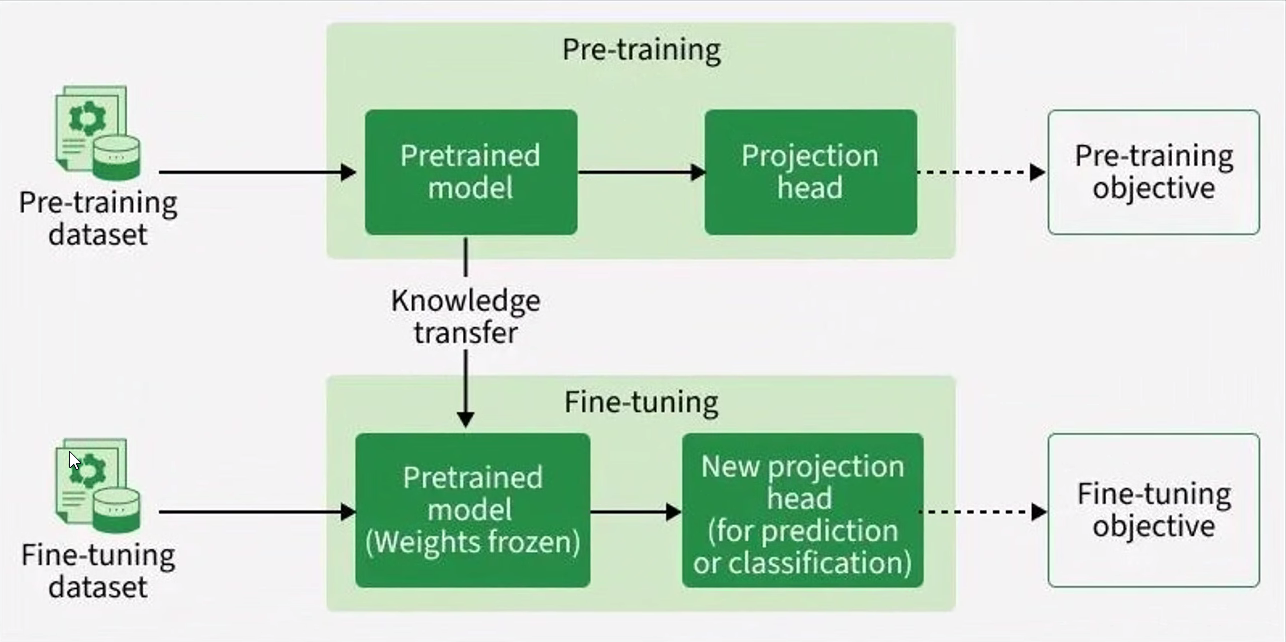

In [4]:
!pip install -q transformers==4.57.6

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [5]:
import transformers
print(transformers.__version__)

4.57.6


### 목표
- 한국어 분류 데이터셋을 활용한 한국어 토픽 분류 모델 구현
- 데이터 준비부터 파인튜닝(미세조정) 훈련까지의 흐름을 경험해보자
- 모델과 토크나이저, 파인튜닝에 필요한 클래스를 직접 조작하면서 허깅페이스의 내부 동작에 대해 조금 더 깊이 알아보자


In [6]:
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cpu


### YNAT 데이터셋
- 링크 : https://huggingface.co/datasets/klue/klue
- 연합뉴스 기사 제목을 7개 주제로 분류
- 레이블 0~6 : 정치 / 경제 / 사회 / 생활문화 / 세계 / IT과학 / 스포츠

---

```python
> 원출처 : KLUE Benchmark 프로젝트
> - "Korean Language Understanding Evaluation"의 약자  
> - 한국어 자연어 이해(NLU) 전용 종합 벤치마크로 설계  
> - 기계 번역·문장 분류·개체명 인식·관계 추출 등 8개 태스크 포함

> 논문
> - "KLUE: Korean Language Understanding Evaluation"  
> - EMNLP 2021 학회 게재  
> - 한국어 특화 NLU 모델 평가를 위한 표준 데이터셋 및 메트릭 제안

> 대규모 한국어 토픽 분류 데이터 제공 목적  
> - 한국어 NLU 모델의 토픽 분류 성능을 객관적으로 비교·평가  
> - 연구자들이 일관된 지표로 모델 개선 효과를 검증할 수 있도록 지원
```

#### klue 데이터셋 각 Task별 핵심 필드 및 설명

| Task  | 예시 인스턴스 (train) 주요 필드                          | 설명                                                         |
|-------|--------------------------------------------------------|------------------------------------------------------------|
| **ynat** (Topic Classification) | `guid`, `title`, `label`, `date`, `url`                 | 연합뉴스 기사 제목을 7개 주제(0–6)로 분류                          |
| **sts** (Semantic Textual Similarity) | `guid`, `sentence1`, `sentence2`, `labels`               | 두 문장 간 의미 유사도 (float 점수, real-label, binary-label)    |
| **nli** (Natural Language Inference)   | `guid`, `premise`, `hypothesis`, `label`                 | 전제(premise)와 가설(hypothesis) 간 함의 관계(0: entailment, 1: neutral, 2: contradiction)  |
| **ner** (Named Entity Recognition)     | `sentence`, `tokens`, `ner_tags`                         | 문장 문자 단위 토큰별 개체명 태그 (B-*/I-*/O)                     |
| **re** (Relation Extraction)           | `guid`, `sentence`, `subject_entity`, `object_entity`, `label` | 문장 속 두 개체(subject/object) 간 관계 분류                       |
| **dp** (Dependency Parsing)            | `sentence`, `index`, `word_form`, `lemma`, `pos`, `head`, `deprel` | 형태소 단위 의존 구문 분석 (head, deprel)                        |
| **mrc** (Machine Reading Comprehension) | `title`, `context`, `question`, `answers`, `is_impossible`, `news_category` | 지문(context)과 질문(question)에 대한 정답(answer) 스팬 추출      |
| **wos** (Dialogue State Tracking)      | `guid`, `domains`, `dialogue`                            | 대화(turn)별 사용자·시스템 발화와 상태(state) 추적                   |


In [7]:
# 데이터 불러오기
from datasets import load_dataset # 허깅페이스 데이터 로드용 함

In [8]:
ds = load_dataset("klue/klue", "ynat")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

ynat/train-00000-of-00001.parquet:   0%|          | 0.00/4.17M [00:00<?, ?B/s]

ynat/validation-00000-of-00001.parquet:   0%|          | 0.00/847k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45678 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/9107 [00:00<?, ? examples/s]

In [9]:
ds

# DatasetDict : 허깅페이스의 자료형
# 여러 데이터셋을 담는 dict 형태

DatasetDict({
    train: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date'],
        num_rows: 45678
    })
    validation: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date'],
        num_rows: 9107
    })
})

In [10]:
ds.keys()

# 학습용 / 검증용 데이터로 제공

dict_keys(['train', 'validation'])

In [11]:
# 첫 번째 학습 데이터 예시 확인
ds['train'][0]


{'guid': 'ynat-v1_train_00000',
 'title': '유튜브 내달 2일까지 크리에이터 지원 공간 운영',
 'label': 3,
 'url': 'https://news.naver.com/main/read.nhn?mode=LS2D&mid=shm&sid1=105&sid2=227&oid=001&aid=0008508947',
 'date': '2016.06.30. 오전 10:36'}

In [12]:
# 데이터프레임 형태로 확인 가능
ds['train'].to_pandas()

,guid,title,label,url,date
0,ynat-v1_train_00000,유튜브 내달 2일까지 크리에이터 지원 공간 운영,3,https://news.naver.com/main/read.nhn?mode=LS2D...,2016.06.30. 오전 10:36
1,ynat-v1_train_00001,어버이날 맑다가 흐려져…남부지방 옅은 황사,3,https://news.naver.com/main/read.nhn?mode=LS2D...,2016.05.08. 오전 5:25
2,ynat-v1_train_00002,내년부터 국가RD 평가 때 논문건수는 반영 않는다,2,https://news.naver.com/main/read.nhn?mode=LS2D...,2016.03.15. 오후 12:00
3,ynat-v1_train_00003,김명자 신임 과총 회장 원로와 젊은 과학자 지혜 모을 것,2,https://news.naver.com/main/read.nhn?mode=LS2D...,2017.02.28. 오전 9:54
4,ynat-v1_train_00004,회색인간 작가 김동식 양심고백 등 새 소설집 2권 출간,3,https://news.naver.com/main/read.nhn?mode=LS2D...,2018.04.03. 오전 7:05
...,...,...,...,...,...
45673,ynat-v1_train_45673,사우디 아람코 주요 석유시설·유전 드론 공격에 화재,4,https://news.naver.com/main/read.nhn?mode=LS2D...,2019.09.14. 오후 4:36
45674,ynat-v1_train_45674,박기원 감독 눈치 보지 말고…비예나 눈치 본 건 아닌데,5,https://sports.news.naver.com/news.nhn?oid=001...,2019.11.03 17:06
45675,ynat-v1_train_45675,아시안게임 첫 경기 앞둔 라건아 인도네시아 팬이라도 ...,5,https://sports.news.naver.com/news.nhn?oid=001...,2018.08.13 17:54
45676,ynat-v1_train_45676,트럼프 미중 무역협상 1단계 합의 서명식 가질 것종합,4,https://news.naver.com/main/read.nhn?mode=LS2D...,2019.12.25. 오후 4:36


### 허깅페이스 파인튜닝 워크플로우
> 데이터 -> Tokenizer -> DataCollator -> model -> Trainner -> 결과

- Tokenizer : 토큰화 도구
사전학습 때 사용된 토큰화 도구를 사용해서 입력 데이터를 처리
- DataCollator : 규격화 통
  - 입력 데이터를 일정한 크기로 맞춰줌(패딩 처리 등)
- Trainner : 관리자
  - 데이터 전처리 ~ 학습, 평가, 저장까지 모든 과정을 한번에 수행해주는 API

#### monologg/koelectra 주요 버전 및 종류

- GitHub : https://github.com/monologg/KoELECTRA/blob/master/README.md

| 모델 이름                                       | 크기    | 역할            | 설명                                                         |
| ------------------------------------------- | ----- | ------------- | ---------------------------------------------------------- |
| `monologg/koelectra-base-generator`         | Base  | Generator     | 토큰 생성기(generator) 역할 · v3 이전 버전         |
| `monologg/koelectra-base-discriminator`     | Base  | Discriminator | 토큰 판별기(discriminator) 역할 · v1/v2 기본 버전  |
| `monologg/koelectra-base-v3-generator`      | Base  | Generator     | v3 버전 · generator                       |
| `monologg/koelectra-base-v3-discriminator`  | Base  | Discriminator | v3 버전 · discriminator                   |
| `monologg/koelectra-small-generator`        | Small | Generator     | 소형 모델 · generator                       |
| `monologg/koelectra-small-discriminator`    | Small | Discriminator | 소형 모델 · discriminator                   |
| `monologg/koelectra-small-v3-generator`     | Small | Generator     | v3 소형 버전 · generator (NSMC 감성분석 등에 활용 가능)                  |
| `monologg/koelectra-small-v3-discriminator` | Small | Discriminator | v3 소형 버전 · discriminator (감정분석, 문장분류 등)                    |
| `monologg/koelectra-small-v3-goemotions`    | Small | Discriminator | v3 소형 버전 · GoEmotions 감정분류용 (영문 감정 레이블 매핑)                 |
| `monologg/koelectra-base-v3-naver-ner`      | Base  | Discriminator | v3 버전 · Naver NER(개체명 인식)용 fine-tuned 모델                   |
| `monologg/koelectra-base-v3-gender-bias`    | Base  | Discriminator | v3 버전 · 성별 편향 분석용 (gender-bias) 모델                         |

In [13]:
from transformers import AutoTokenizer

In [14]:
# 토크나이저 불러오기
model_name = 'monologg/koelectra-base-v3-discriminator'

In [15]:
tokenizer = AutoTokenizer.from_pretrained(
    model_name, # 토크나이저 이름
    clean_up_tokenization_spaces = True # 토큰화 후에 공백 문자 등을 정리하는 옵션 (기본값으로는 True)
)

tokenizer_config.json:   0%|          | 0.00/61.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

In [16]:
# 하나의 문장(뉴스 제목) 토큰화 테스트
ds['train'][0]['title']

'유튜브 내달 2일까지 크리에이터 지원 공간 운영'

In [17]:
temp = tokenizer(
    ds['train'][0]['title'], # 토큰화 대상
    truncation = True, # 최대 토큰 길이 넘으면 자르기
    max_length = 128 # 토큰 최대 길이 설정
)

In [18]:
temp

# 'input_ids': 토큰 ID 리스트
# 'token_type_ids' : 문장 구분 ID(현재는 단일 문장으로 다 0)
# 'attention_mask' : 패딩 부여 0, 실제 토큰은 1

{'input_ids': [2, 11468, 11642, 22, 4366, 4149, 4200, 32462, 6310, 6800, 6411, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [19]:
# 토크나이저 함수 정의
def tokenize_function(ex) :
  return tokenizer(ex['title'], truncation = True, max_length = 128)

- 데이터에 토크나이저를 적용하기 위한 함수 종류

> #### **map()**
> - **<U>변환을 즉시 적용**</U>하며, 변환된 결과는 새로운 데이터셋으로 반환됨
> - 토큰화, 라벨 변환 등 데이터 전처리 작업에서 자주 사용

> #### **with_transform()**
> - 변환을 등록해 두고, 실제 **<U>데이터 접근 시 변환을 적용**</U>함 (스트림형)
> - 학습을 수행할 때 호출하여 변형이 이루어짐
> - 메모리 절약을 위해, 또는 데이터셋을 한 번에 모두 변형할 필요가 없을 때 유용

In [20]:
# 데이터셋(학습용/검증용 모두)에 토크나이저 적용
tokenized_ds = ds.map(
    tokenize_function, # 토크나이저 함수

    # 동작 방식 설정
    batched = True # -> 데이터를 하나씩 전달하지 않고 여러개 모아서 전달 -> 속도 향상
)

Map:   0%|          | 0/45678 [00:00<?, ? examples/s]

Map:   0%|          | 0/9107 [00:00<?, ? examples/s]

In [21]:
tokenized_ds

# features에 기존 정보 + 토크나이저 적용된 정보

DatasetDict({
    train: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 45678
    })
    validation: Dataset({
        features: ['guid', 'title', 'label', 'url', 'date', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9107
    })
})

In [22]:
tokenized_ds['train'][0]

{'guid': 'ynat-v1_train_00000',
 'title': '유튜브 내달 2일까지 크리에이터 지원 공간 운영',
 'label': 3,
 'url': 'https://news.naver.com/main/read.nhn?mode=LS2D&mid=shm&sid1=105&sid2=227&oid=001&aid=0008508947',
 'date': '2016.06.30. 오전 10:36',
 'input_ids': [2,
  11468,
  11642,
  22,
  4366,
  4149,
  4200,
  32462,
  6310,
  6800,
  6411,
  3],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [23]:
# 훈련에 필요하지 않는 컬럼 제거
# 훈련에 필요한 컬럼(features) : 'label', 'input_ids', 'token_ids', 'attention_mask'
tokenized_ds = tokenized_ds.remove_columns(['guid', 'title', 'url', 'date'])

In [24]:
tokenized_ds

# 정답데이터(label) + 토크화된 결과만 남아있는 상태!

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 45678
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9107
    })
})

In [25]:
# 결과를 해석하기 쉽게 모델 설정에서 레이블 이름 등록
label_names = tokenized_ds['train'].features['label'].names
label_names

['IT과학', '경제', '사회', '생활문화', '세계', '스포츠', '정치']

In [26]:
# 숫자 : 정답 / 정답 : 숫자
# 라벨(정답이름) : ID(숫자) 변환할 수 있도록 딕셔너리 생성
id2label = {i : name for i,name in enumerate(label_names)}
# enumerate(label_names) : [(0,'IT과학'), (1,'경제') ... (6,'정치')]
label2id = {name : i for i,name in enumerate(label_names)}
print(id2label)
print(label2id)

{0: 'IT과학', 1: '경제', 2: '사회', 3: '생활문화', 4: '세계', 5: '스포츠', 6: '정치'}
{'IT과학': 0, '경제': 1, '사회': 2, '생활문화': 3, '세계': 4, '스포츠': 5, '정치': 6}


In [27]:
# 사전학습 된 모델 불러오기
from transformers import AutoModelForSequenceClassification

In [28]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, # 사전학습 모델 이름
    num_labels = len(label_names) # 분류할 라벨의 클래스 개수 지정
)

pytorch_model.bin:   0%|          | 0.00/452M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/452M [00:00<?, ?B/s]

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at monologg/koelectra-base-v3-discriminator and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [29]:
# up-steram(업스트림) : 모델이 일반적인 언어 패턴을 배우는 사전학습 과정
# down-stream(다운스트림) : 사전학습된 모델을 특정 작업에 맞게 조정하는 파인튜닝 과정

# You should probably TRAIN this model on a down-stream task ...
# 파인튜닝을 거쳐야 제대로 학습되서 예측 및 추론이 가능하다는 안내 문구

In [30]:
model.config.id2label

{0: 'LABEL_0',
 1: 'LABEL_1',
 2: 'LABEL_2',
 3: 'LABEL_3',
 4: 'LABEL_4',
 5: 'LABEL_5',
 6: 'LABEL_6'}

In [31]:
model.config.label2id

{'LABEL_0': 0,
 'LABEL_1': 1,
 'LABEL_2': 2,
 'LABEL_3': 3,
 'LABEL_4': 4,
 'LABEL_5': 5,
 'LABEL_6': 6}

In [32]:
model.config.id2label = id2label
model.config.label2id = label2id
# 모델 설정값에 라벨 이름 매핑한 데이터로 업데이트

In [33]:
model.config.id2label

{0: 'IT과학', 1: '경제', 2: '사회', 3: '생활문화', 4: '세계', 5: '스포츠', 6: '정치'}

In [34]:
# DataCollator : 길이가 다를 수 있는 입력값들의 길이를 통일해주는 작업
# 평가지표 함수 정의 : 검증단계에서 계산할 평가지표 함수(정확도, 정밀도, 재현율, F1 등)


In [35]:
# DataCollator 불러오기
from transformers import DataCollatorWithPadding

# 동적으로 배치 내 최장 길이 (128)에 맞춰서 패딩해서
# trainer에게 전달해주는 도구

In [36]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
# 토큰화하는데 사용했던 토큰나이저 지정

# 이유?
# 패딩 부여 기준 정보를 제공하기 위해

In [37]:
# 검증데이터를 활용해서 테스트(모델 입출력 구조 확인)

# 1. 예측에 사용할 모델 입력 만들기

# 모델을 GPU(or CPU) 환경에서 사용할 수 있도록 세팅
model = model.to(device)

In [38]:
# 검증용 데이터에서 샘플 추출
sample = tokenized_ds['validation'][0]

In [39]:
sample.keys()

dict_keys(['label', 'input_ids', 'token_type_ids', 'attention_mask'])

In [40]:
# 모델에 입력 데이터로 전달하기 위해 사용할 특성(label 제외) 추출
# 라벨을 제외한 특성만 뽑아서 Tensor 변환 후 GPU로 전달

use_columns = ['input_ids', 'token_type_ids', 'attention_mask']

In [41]:
inputs = {}

for key,value in sample.items(): # key, value가 튜플에 담겨있음
  if key in use_columns: # key값이 사용할 컬럼인지 확인
    tensor = torch.tensor(value) # list -> Pytorch Tensor 변환
    tensor = tensor.unsqueeze(0) # 차원 추가 -> 모델은 배치 단위로 입력([batchsize, seq_len])
    tensor = tensor.to(device) # GPU 사용시 모델과 동일한 위치로 tensor 이동

    # 딕셔너리 추가
    inputs[key] = tensor
inputs

{'input_ids': tensor([[    2,    25,  4639,  4005, 23362, 18075,  4034,  2411,  4219,    27,
           4156,  4172,  4005,  6874,  4164,  4034,  3081,  4880,  4176,     3]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [42]:
sample.items()

dict_items([('label', 2), ('input_ids', [2, 25, 4639, 4005, 23362, 18075, 4034, 2411, 4219, 27, 4156, 4172, 4005, 6874, 4164, 4034, 3081, 4880, 4176, 3]), ('token_type_ids', [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), ('attention_mask', [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])])

In [43]:
# 정답 label도 tensor 변환
labels = sample['label']
labels_tensor = torch.tensor([labels]) # [label] 모양의 tensor 생성
labels_tensor = labels_tensor.to(device) # GPU 사용시 모델과 동일한 위치로 tensor 이동
labels_tensor

tensor([2])

In [44]:
# 모델 예측 해보기
# no_grad() : 예측할때는 gradient(기울기) 계산은 불필요함 -> 메모리/연산 절약을 위해 기울기 계산 비활성화
with torch.no_grad() :
  outputs = model(**inputs)

In [45]:
outputs

SequenceClassifierOutput(loss=None, logits=tensor([[-0.0100, -0.0274, -0.0828,  0.0442, -0.0357,  0.0221, -0.0695]]), hidden_states=None, attentions=None)

In [46]:
# 모델의 성능을 파악하기 위한 평가지표 설정
# sklearn 활용 -> numpy 배열 활용
import numpy as np

In [47]:
# logits 값을 CPU로 가져와서 넘파이 배열로 변환
logits = outputs.logits.cpu().numpy()
logits # tensor -> ndarray

array([[-0.00996318, -0.02744989, -0.08283789,  0.04418209, -0.03567772,
         0.02210499, -0.06945208]], dtype=float32)

In [48]:
# 예측값 - 실제값 비교
pred = np.argmax(logits)
print(f'예측값 : {pred}, {model.config.id2label[pred]}')
print(f'실제값 : {labels}, {model.config.id2label[labels]}')

예측값 : 3, 생활문화
실제값 : 2, 사회


In [49]:
ds['validation'][0]

{'guid': 'ynat-v1_dev_00000',
 'title': '5억원 무이자 융자는 되고 7천만원 이사비는 안된다',
 'label': 2,
 'url': 'https://news.naver.com/main/read.nhn?mode=LS2D&mid=shm&sid1=101&sid2=260&oid=001&aid=0009563542',
 'date': '2017.09.21. 오후 5:09'}

In [50]:
# 평가 도구 불러오기
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# accuracy : 정확도 -> 전체 데이터중에서 몇 개를 맞혔는지 (TP + TN / TP + TN + FP +FN)
# precision : 정밀도 -> 특정 클래스로 예측한 것 중 실제 정답인 비율( TP / TP + FP)
# recall : 재현율 -> 실제 양성인 데이터에서 예측 양성의 비율(TP / TP + FN)
#                    특정 주제에 대해 예측과 실제 값이 일치한 데이터의 비율
# f1 스코어 : 정밀도와 재현율의 조화 평균

In [52]:
# sklearn의 평가 함수에 전달하기 위해 labels도 동일하게 CPU로 가져와서 넘파이 배열로 변환

labels = labels_tensor.cpu().numpy()
labels

array([2])

In [54]:
# 단일 예측값을 1차원 배열로 변환
preds = np.array([pred])
preds

array([3])

In [55]:
# 평가 함수의 인자값 : 실제값(y_true), 예측값(y_pred)

# 정확도 계산
acc = accuracy_score(labels, preds)

0.0

In [57]:
# 정밀도, 재현율, f1스코어 계산
prec, rec, f1, _ = precision_recall_fscore_support(
# 결과값이 정밀도, 재현율, f1, 각 클래스별 표본수(support)
# support는 우리는 쓰지 않을 예정으로 '_' 설정(변수 할당 X)
    labels,
    preds,
    zero_division = 0, # 분모가 0이 되는 경우 결과를 0으로 처리
    average = 'macro'  # 각 주제별 평가 점수 계산한 다음 모든 주제를 동일한 비중으로 평균
                       # 데이터가 많은 주제만 평가에 큰 영향을 미치는 것을 줄이고, 각 주제를 균등하게 평가
                       # 클래스가 불균형 상황에서도 각 클래스 성능을 동등하게 평가
)

prec, rec, f1, _

(0.0, 0.0, 0.0, None)

In [59]:
# trainner에 전달할 평가지표 함수 정의
def compute_metrics(eval_pred):
    """
    Trainer가 사용하는 평가지표 함수
    - eval_pred : (logits, labels) 튜플
    """
    logits, labels = eval_pred
    preds = np.argmax(logits, axis = 1) # axis=1: 두 번째 축(열 방향, 즉 클래스 차원)에서 최대값의 인덱스를 찾으라는 의미
                                        # 결과는 (batch_size,) 모양의 1차원 배열로, 각 샘플별 예측 클래스 ID가 들어있음

    # 정확도
    acc = accuracy_score(labels, preds)

    # 정밀도, 재현율, F1 (macro average)
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average = "macro")
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

In [60]:
# 학습 과정에서 필요한 하이퍼파라미터들을 설정하는 도구(클래스)
# 학습률, 배치크기, 에포크 등 학습 관련 설정 관리
from transformers import TrainingArguments

In [61]:
batch_size = 32
# 배치 크기가 크면 메모리 사용량 증가
# 배치 크기가 작으면 메모리 사용랑 줄어들지만 손실값 불안정할 수 있음

# 학습에 필요한 하이퍼파라미터 및 설정 세팅
training_args = TrainingArguments(
    output_dir = 'data/ynat-model', # 학습결과(모델 가중치, 체크포인트) 저장 경로
    num_train_epochs = 3, # 학습할 에포크 수
    per_device_train_batch_size = batch_size, # 학습에 사용할 배치 크기
    per_device_eval_batch_size = batch_size, # 검증 시 배치 크기
    learning_rate = 5e-5, # 학습률(0.00005 : BERT계열 모델에 흔히 쓰이는 값)
    eval_strategy = 'epoch', # 검증 전략, 각 'epoch'이 끝날 때 검증
    logging_steps = 50, # 학습 중간에 로그를 찍는 간격
    save_strategy = 'epoch', # 모델 저장 전략, 'steps' 도 있음
    load_best_model_at_end = True, # 검증 성능이 최고인 체크포인트를 마지막에 불러옴
    metric_for_best_model = 'accuracy', # 최고 모델 판단에 사용할 평가지표
    push_to_hub = False, # 학습 후 수동으로 push 예정
    report_to = 'none' # 활성화 시 api키를 요구하므로 none 설정
)

In [62]:
# trainer 불러오기
# 모델 훈련을 간소화 해주는 고수준 API
# training arguments, 모델, 데이터셋, collator, 평가함수 등을 인자로 받아서 내부에서 학습 루프 관리

from transformers import Trainer

In [64]:
# 학습 객체 생성
trainer = Trainer(
    model = model, # 사전학습 모델
    args = training_args, # 학습 시 필요한 하이퍼파라미터 설정(ex> 학습률, 학습 횟수 등)
    train_dataset = tokenized_ds['train'],
    eval_dataset = tokenized_ds['validation'],
    data_collator = data_collator,
    processing_class = tokenizer,
    compute_metrics = compute_metrics
)

In [ ]:
# 학습
trainer.train()

# global_step : 전체 학습 스텝 수 (배치 크기에 따라서 달라짐)
# trainig_loss : 학습 데이터셋에서 계산된 평균 손실값
# 'train_runtime' : 학습에서 걸린 총 시간(초)
# train_samples_per_second : 초당 처리한 샘플 수
# train_steps_per_second : 초당 수행한 학습 스텝수
# total_flos : 학습에 사용된 총 부동소수점 연산량
# train_loss : 최종 훈련 데이터셋 손실값

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


In [ ]:
# 검증데이터셋에 대한 최종 평가
trainer.evaluate()

# eval_loss : 검증셋 평균 손실값
# eval_accuracy : 검증셋 정확도
# eval_precision : 검증셋 정밀도 (Average = 'macro') -> 전체(라벨 0~6)에 대한 평균값 확인
# ...

In [ ]:
# 혼동행렬을 통해 어떤 주제에서 오분류가 발생하는지 확인

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
# 검증셋으로 예측 수행해보기
pred_res = trainer.predint(tokenized_ds['validation'])

In [ ]:
pred_res
# PredictionOutput : 예측한 결과값
# predictions : 모델의 logits 배열 (데이터 개수 x 라벨 개수) -> (9107, 7)
# label_ids : 실제 예측 라벨 배열

In [ ]:
# 실제 라벨 추출
t_true = pred_res.label_ids

In [ ]:
# 예측 라벨 추출
y_pred = np.argmax(pred_res.predictions, axis = 1) # logits 배열에서 가장 큰 값의 인덱스 추출

In [ ]:
# 혼동행렬 생성
confusion_matrix(y_true, y_pred)

# 히트맵으로 표현하면 한눈에 보기 쉽다!